In [1]:
# CELL 1: imports and load
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
sns.set_theme(style="whitegrid")
test_ds = pd.read_csv("../data/interim/model_predictions_test.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
lobo_ds = pd.read_csv("../data/interim/model_predictions_lobo.csv", parse_dates=["ArrivalDate", "ExpiryDate"])
THRESHOLD = float(test_ds["Threshold"].iloc[0])          # the ONE threshold used everywhere
dev_ds = lobo_ds[~lobo_ds["BatchID"].isin(test_ds["BatchID"])].copy()

In [2]:
# CELL 2: test evaluation (test rows only) and naive baselines
print(classification_report(test_ds["IsSpoiled"], test_ds["RF_Pred"], target_names=["Not spoiled", "Spoiled"], zero_division=0))
print(confusion_matrix(test_ds["IsSpoiled"], test_ds["RF_Pred"]))
print(f"Baseline 'flag everything': recall 1.00, precision {test_ds['IsSpoiled'].mean():.2f}")

              precision    recall  f1-score   support

 Not spoiled       0.00      0.00      0.00       163
     Spoiled       0.11      1.00      0.20        21

    accuracy                           0.11       184
   macro avg       0.06      0.50      0.10       184
weighted avg       0.01      0.11      0.02       184

[[  0 163]
 [  0  21]]
Baseline 'flag everything': recall 1.00, precision 0.11


In [3]:
# CELL 3: redistribution cut-offs, tested on DEV rows only (never on test)
base_rate = dev_ds["IsSpoiled"].mean()
rows = []
for gap in [-1, -2, -3]:                       # nearby stores sell more than this many units/day faster
    for q in [0.25, 0.5, 0.75]:                # how far away a store may be (distance quantile)
        dist = dev_ds["DistanceToNearestStore"].quantile(q)
        flagged = (dev_ds["Sales_vs_Nearby_Gap"] < gap) & (dev_ds["DistanceToNearestStore"] <= dist)
        rows.append({"gap_below": gap, "distance_quantile": q, "max_km": round(dist, 1), "rows_flagged": int(flagged.sum()),
                     "precision": round(dev_ds.loc[flagged, "IsSpoiled"].mean(), 2) if flagged.sum() else np.nan,
                     "spoiled_covered": round(dev_ds.loc[flagged, "IsSpoiled"].sum() / dev_ds["IsSpoiled"].sum(), 3)})
grid_table = pd.DataFrame(rows); print(grid_table)
ok = grid_table[grid_table["precision"] >= base_rate]      # keep only rules at least as precise as the base rate
chosen = (ok if len(ok) else grid_table).sort_values("spoiled_covered", ascending=False).iloc[0]
GAP_CUT, DIST_CUT = float(chosen["gap_below"]), float(chosen["max_km"])
print("dev base rate:", round(base_rate, 2), "| chosen: gap <", GAP_CUT, "and distance <=", DIST_CUT, "km")

   gap_below  distance_quantile  max_km  rows_flagged  precision  \
0         -1               0.25     4.9            47       0.43   
1         -1               0.50     8.1            97       0.49   
2         -1               0.75    11.6           144       0.47   
3         -2               0.25     4.9            22       0.45   
4         -2               0.50     8.1            36       0.50   
5         -2               0.75    11.6            61       0.44   
6         -3               0.25     4.9             6       0.50   
7         -3               0.50     8.1             8       0.62   
8         -3               0.75    11.6            14       0.43   

   spoiled_covered  
0            0.048  
1            0.115  
2            0.161  
3            0.024  
4            0.043  
5            0.065  
6            0.007  
7            0.012  
8            0.014  
dev base rate: 0.51 | chosen: gap < -3.0 and distance <= 8.1 km


In [4]:
# CELL 4: recommendation with one threshold: flagged AND can_move -> redistribute; flagged only -> discount; else normal
def recommend(df):
    flagged = df["RF_Prob"] >= THRESHOLD
    can_move = (df["Sales_vs_Nearby_Gap"] < GAP_CUT) & (df["DistanceToNearestStore"] <= DIST_CUT)
    return np.where(flagged & can_move, "redistribute", np.where(flagged, "discount/promotion", "normal"))
test_ds["Priority_Score"] = test_ds["StockQty"] * test_ds["RF_Prob"]
test_ds["Redistribution_Candidate"] = (test_ds["Sales_vs_Nearby_Gap"] < GAP_CUT) & (test_ds["DistanceToNearestStore"] <= DIST_CUT)
test_ds["Recommended_Action"] = recommend(test_ds)
print(test_ds["Recommended_Action"].value_counts())

Recommended_Action
discount/promotion    181
redistribute            3
Name: count, dtype: int64


In [5]:
# CELL 5: priority check on test rows only
top20 = test_ds.sort_values("Priority_Score", ascending=False).head(20)
print("Of the top 20 by units at risk, truly spoiled:", int(top20["IsSpoiled"].sum()), "/ 20")
print("Test spoiled rate for comparison:", round(test_ds["IsSpoiled"].mean(), 2))

Of the top 20 by units at risk, truly spoiled: 0 / 20
Test spoiled rate for comparison: 0.11


In [6]:
# CELL 6: business impact. Units come from the data. Price, markdown and effectiveness are ASSUMPTIONS to justify.
def impact(df, label):
    exposed = df.loc[df["IsSpoiled"], "StockQty"].sum()
    caught = df.loc[df["IsSpoiled"] & (df["RF_Pred"] == 1), "StockQty"].sum()
    false_alarm = df.loc[(~df["IsSpoiled"]) & (df["RF_Pred"] == 1), "StockQty"].sum()
    return {"Evidence": label, "Units in batches that spoiled": int(exposed), "Units flagged in time": int(caught),
            "Units flagged needlessly": int(false_alarm), "Share of exposed units flagged": round(caught / exposed, 2)}
impact_table = pd.DataFrame([impact(test_ds, "Test rows (10 batches, 1 spoiled)"),
                             impact(lobo_ds, "All 50 batches, leave-one-batch-out")])
print(impact_table.T)
UNIT_PRICE = 20.0                              # pula per unit: replace with a justified average shelf price
for effect in [0.10, 0.21, 0.50]:              # share of flagged units actually saved by acting
    saved = impact_table.iloc[1]["Units flagged in time"] * effect
    print(f"saves {effect:.0%}: {saved:,.0f} units = P{saved * UNIT_PRICE:,.0f}")
needless_cost = impact_table.iloc[1]["Units flagged needlessly"] * 0.3 * UNIT_PRICE   # 30% markdown assumption
print(f"cost of needless markdowns: P{needless_cost:,.0f}")
print(f"break-even effectiveness: {needless_cost / (impact_table.iloc[1]['Units flagged in time'] * UNIT_PRICE):.0%}")

                                                                0  \
Evidence                        Test rows (10 batches, 1 spoiled)   
Units in batches that spoiled                                2100   
Units flagged in time                                        2100   
Units flagged needlessly                                    30625   
Share of exposed units flagged                                1.0   

                                                                  1  
Evidence                        All 50 batches, leave-one-batch-out  
Units in batches that spoiled                                 74987  
Units flagged in time                                         67497  
Units flagged needlessly                                      81944  
Share of exposed units flagged                                  0.9  
saves 10%: 6,750 units = P134,994
saves 21%: 14,174 units = P283,487
saves 50%: 33,748 units = P674,970
cost of needless markdowns: P491,664
break-even effectiveness

In [7]:
# CELL 7: export test rows only (columns match your existing Power BI file)
test_ds["Nearby_Demand_Gap"] = (-test_ds["Sales_vs_Nearby_Gap"]).round(1)
test_ds["DataSplit"] = "Test"
export_cols = ["ItemName", "Brand", "Category", "StoreLocation", "StoreID", "Zone", "ArrivalDate", "ExpiryDate",
               "DaysUntilExpiry", "StockQty", "DailySaleAvg", "OnPromotion", "TemperatureSensitive", "IsSpoiled",
               "RF_Prob", "RF_Pred", "Priority_Score", "Redistribution_Candidate", "Sales_vs_Nearby_Gap",
               "DistanceToNearestStore", "Nearby_Demand_Gap", "Recommended_Action", "DataSplit"]
test_ds[export_cols].to_csv("../outputs/powerbi/smart_waste_dashboard_data.csv", index=False)

In [8]:
# One function colours any action label: amber = move, red = discount, green = normal.
# It matches on the first letters, so a spelling slip like "discout" still works.
def action_color(label):
    label = label.lower()
    if label.startswith("redis"): return COLOR_WARN
    if label.startswith("disc"):  return COLOR_SPOILED
    return COLOR_SAFE
action_palette = {a: action_color(a) for a in dataset["Recommended_Action"].unique()}

In [9]:
# The 10 biggest "units at risk" among test items the model told us to act on.
act = test_only[test_only["Recommended_Action"].str.lower() != "normal"]
top10 = act.sort_values("Priority_Score", ascending=False).head(10).copy()
top10["Label"] = top10["ItemName"] + " (" + top10["StoreID"] + ")"
plt.figure(figsize=(11, 5))
sns.barplot(data=top10, x="Priority_Score", y="Label", hue="Recommended_Action",
            palette=action_palette, dodge=False, orient="h")
plt.title("Where the units at risk are concentrated: act on these first", fontsize=12, weight="bold")
plt.xlabel("Units at risk (stock x spoilage probability)"); plt.ylabel("")
plt.legend(title="Recommended action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval_2_top_priority.png", dpi=150)
plt.show()

KeyError: 'Recommended_Action'

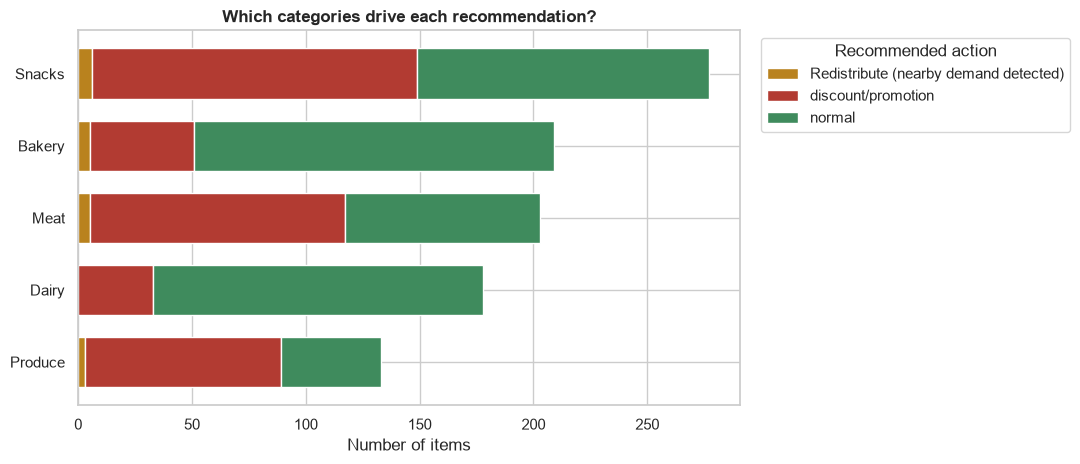

In [ ]:
# Counts each action per category, using all 1,000 rows (a description of the history).
counts = pd.crosstab(dataset["Category"], dataset["Recommended_Action"])
counts = counts.loc[counts.sum(axis=1).sort_values().index]
counts.plot(kind="barh", stacked=True, color=[action_palette[c] for c in counts.columns],
            figsize=(11, 4.8), width=0.7)
plt.title("Which categories drive each recommendation?", fontsize=12, weight="bold")
plt.xlabel("Number of items"); plt.ylabel("")
plt.legend(title="Recommended action", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval_3_actions_by_category.png", dpi=150)
plt.show()

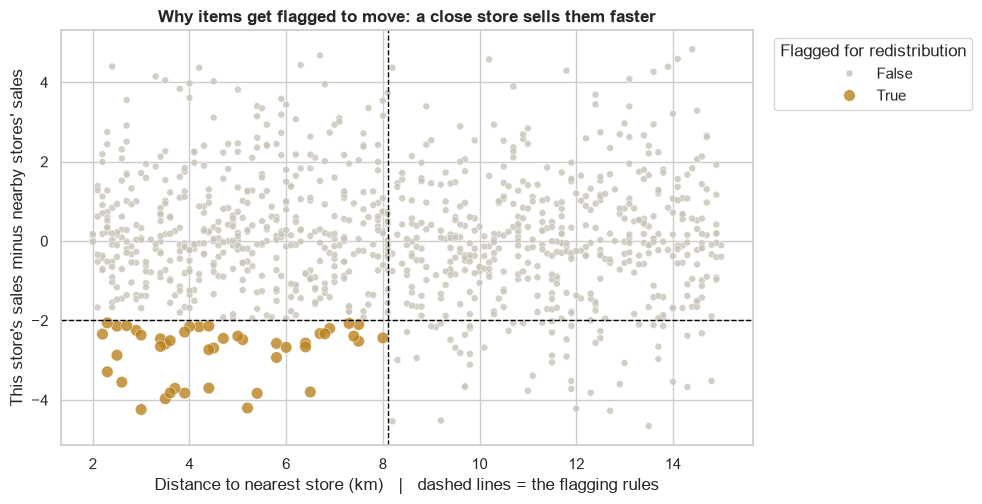

In [ ]:
# Each dot is one item; amber dots passed both redistribution rules (below the dashed horizontal line,
# left of the dashed vertical line).
median_distance = dataset["DistanceToNearestStore"].median()
plt.figure(figsize=(10, 5.2))
sns.scatterplot(data=dataset, x="DistanceToNearestStore", y="Sales_vs_Nearby_Gap",
                hue="Redistribution_Candidate", palette={False: "#C9C4B8", True: COLOR_WARN},
                size="Redistribution_Candidate", sizes={False: 25, True: 70}, alpha=0.8)
plt.axhline(-2, color="black", linestyle="--", linewidth=1)
plt.axvline(median_distance, color="black", linestyle="--", linewidth=1)
plt.title("Why items get flagged to move: a close store sells them faster", fontsize=12, weight="bold")
plt.xlabel("Distance to nearest store (km)   |   dashed lines = the flagging rules")
plt.ylabel("This store's sales minus nearby stores' sales")
plt.legend(title="Flagged for redistribution", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval_4_redistribution_logic.png", dpi=150)
plt.show()

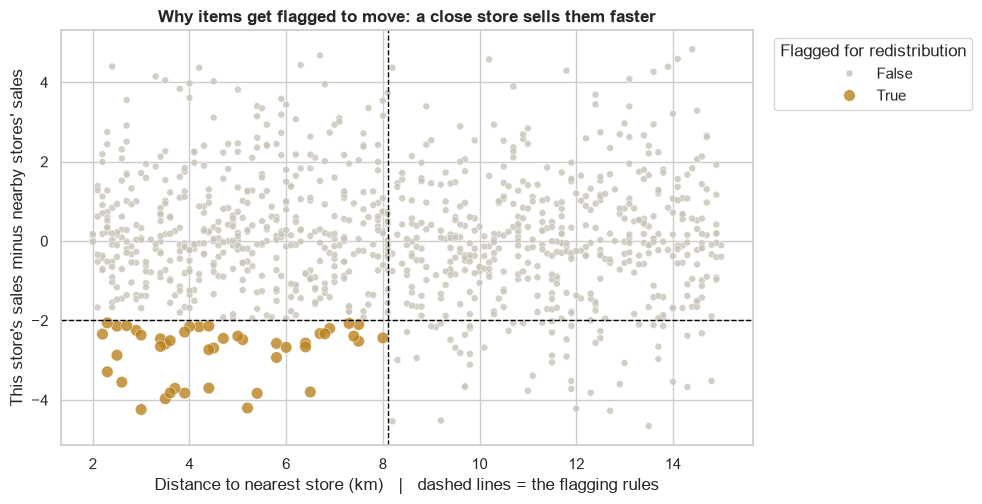

In [ ]:
# Each dot is one item; amber dots passed both redistribution rules (below the dashed horizontal line,
# left of the dashed vertical line).
median_distance = dataset["DistanceToNearestStore"].median()
plt.figure(figsize=(10, 5.2))
sns.scatterplot(data=dataset, x="DistanceToNearestStore", y="Sales_vs_Nearby_Gap",
                hue="Redistribution_Candidate", palette={False: "#C9C4B8", True: COLOR_WARN},
                size="Redistribution_Candidate", sizes={False: 25, True: 70}, alpha=0.8)
plt.axhline(-2, color="black", linestyle="--", linewidth=1)
plt.axvline(median_distance, color="black", linestyle="--", linewidth=1)
plt.title("Why items get flagged to move: a close store sells them faster", fontsize=12, weight="bold")
plt.xlabel("Distance to nearest store (km)   |   dashed lines = the flagging rules")
plt.ylabel("This store's sales minus nearby stores' sales")
plt.legend(title="Flagged for redistribution", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval_4_redistribution_logic.png", dpi=150)
plt.show()

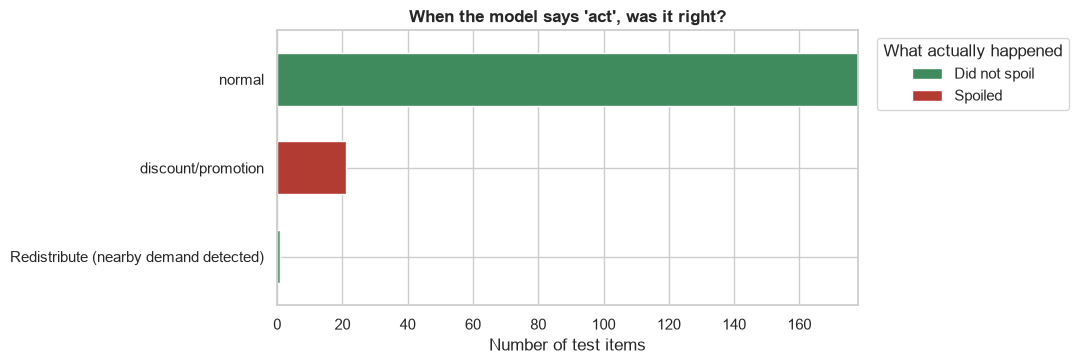

In [ ]:
# For each recommendation, what actually happened to those test items?
check = pd.crosstab(tes=t_only["Recommended_Action"],
                    test_only["IsSpoiled"].map({False: "Did not spoil", True: "Spoiled"}))
for col in ["Did not spoil", "Spoiled"]:       # BREAKS IF: a column is missing; this adds it as zeros
    if col not in check.columns: check[col] = 0
check[["Did not spoil", "Spoiled"]].plot(kind="barh", stacked=True, color=[COLOR_SAFE, COLOR_SPOILED],
                                        figsize=(11, 3.8), width=0.6)
plt.title("When the model says 'act', was it right?", fontsize=12, weight="bold")
plt.xlabel("Number of test items"); plt.ylabel("")
plt.legend(title="What actually happened", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/eval_5_recommendation_vs_reality.png", dpi=150)
plt.show()

In [ ]:
export_cols = [
    "ItemName", "Brand", "Category", "StoreLocation", "StoreID", "Zone",
    "ArrivalDate", "ExpiryDate", "DaysUntilExpiry", "StockQty", "DailySaleAvg",
    "OnPromotion", "TemperatureSensitive", "IsSpoiled",
    "RF_Prob", "RF_Pred", "Priority_Score",
    "Redistribution_Candidate", "Sales_vs_Nearby_Gap", "DistanceToNearestStore",
    "Recommended_Action",
]
dataset[export_cols].to_csv("../outputs/powerbi/smart_waste_dashboard_data.csv", index=False)
print("Exported for Power BI.")

Exported for Power BI.
